In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.linear_model import LogisticRegression, LinearRegression


1. adverserial robustness and
2. Two sources of error in linear regression model:
Mean square error: sum of the differences between the predicted value and the actual value, Bias^2 + variance + eunexplained error
                                                              

 issues affecting reliability
 - underfitting and overfitting
 - when does the model has high bias: when the model is underfitting? model learns less on training data, fitting a linear relationship when it does not exist
 - ![image.png](attachment:05c36047-392e-4f54-a486-cf21cae5885c.png)
 - underfits: common source of error is bias
 - model will underperform on both training and test set when it is underfitted
 - variance is another source of bias: a model has high variance when it follows noise in dataset instead of the patterns , too sensitive on the training data, output changes on every trial
 - model will overfit for variance, random noise is picked up
 - if model overfits, perfomrmance is pure on test, generalizes, affects reliability
 - How to adress overfitting: performs well on training and not test set. cross validation is a method to detect this. **reduce** overfitting through regularization.


 -linear regression: when a model follows random noise, slope and intercept are weights in linear rregression model
 in a model that overfits the slope looks like , and the intercept will be like --
 the weights will be higher
 how to penalize for higher weights: loss function - mean square error + f(x) which is a function of weight
 we need to reduce loss, so we include a function of weights of models to penalize larger weights

 - 3 regularization methods to penalize larger weights:
1. ridge
2. lasso
3. elastic
lasso and ridge regressions:
MSE - mean suquared error: linear reegression

 lasso regularization:
 add a penalty proportion to the absoluete values
 mean square error + (penalty term) lambda * summation of absolute avlues of weights
 lambda- degree of regularization

 Ridge regression:
 adds a penalty proportional to the **square** of the weights
 MSE + lambda into summation of **square** of all the weights

 which ones does feature selection:
 pick one feature over the other, force the weights to zero:
shriinkage facotr depends on beta, both become smaller

 shrinkage factor: slope of penalty term with respect to beta. for lasso function  this factor doesnt depend on beta and is uniform
 aim of optmisation of parameters: find the model parameters where loss function is 0
 hence differentiate the loss function

 hence, lasso forces for feature selections

 remove unwanted variable or noise use lasso regression, ridge will not force coefficients, since shrinakge coeffiecient is dependent on 2 lambda Beta.

elastic net regression
lambda (alpha into summation of all weights plus (1- alpha) into summation of all weights **squared**)
peanlty term is sum of lasso and ridge penalty terms
when alpha is larger: elbert ratio, a number between 0 and 1. lasso is given importance when alpha is large

feature selection: lasso
molticollinearity and keep all predictors : ridge
you want both then use eleastic net - selection _ correlated predictors



In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd
# Load dataset as pandas DataFrame
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
print(df.head()) # First 5 rows
print(df.shape) # (442, 11) -> 10 features + target

df.columns

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
(442, 11)


Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='object')

In [ ]:
X, y = load_diabetes(return_X_y=True)
print(y)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

[151.  75. 141. 206. 135.  97. 138.  63. 110. 310. 101.  69. 179. 185.
 118. 171. 166. 144.  97. 168.  68.  49.  68. 245. 184. 202. 137.  85.
 131. 283. 129.  59. 341.  87.  65. 102. 265. 276. 252.  90. 100.  55.
  61.  92. 259.  53. 190. 142.  75. 142. 155. 225.  59. 104. 182. 128.
  52.  37. 170. 170.  61. 144.  52. 128.  71. 163. 150.  97. 160. 178.
  48. 270. 202. 111.  85.  42. 170. 200. 252. 113. 143.  51.  52. 210.
  65. 141.  55. 134.  42. 111.  98. 164.  48.  96.  90. 162. 150. 279.
  92.  83. 128. 102. 302. 198.  95.  53. 134. 144. 232.  81. 104.  59.
 246. 297. 258. 229. 275. 281. 179. 200. 200. 173. 180.  84. 121. 161.
  99. 109. 115. 268. 274. 158. 107.  83. 103. 272.  85. 280. 336. 281.
 118. 317. 235.  60. 174. 259. 178. 128.  96. 126. 288.  88. 292.  71.
 197. 186.  25.  84.  96. 195.  53. 217. 172. 131. 214.  59.  70. 220.
 268. 152.  47.  74. 295. 101. 151. 127. 237. 225.  81. 151. 107.  64.
 138. 185. 265. 101. 137. 143. 141.  79. 292. 178.  91. 116.  86. 122.
  72. 

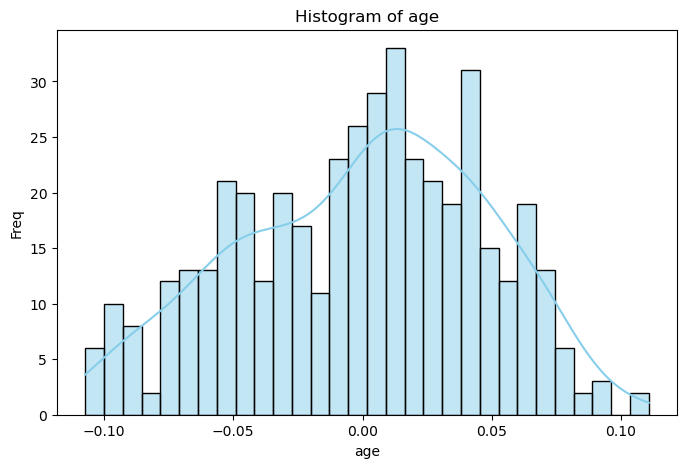

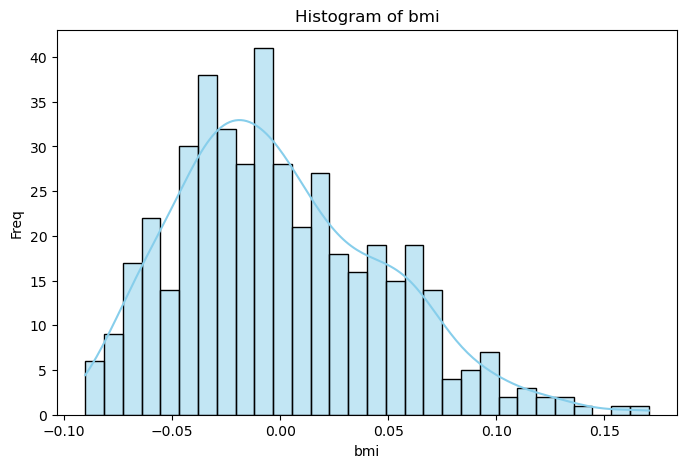

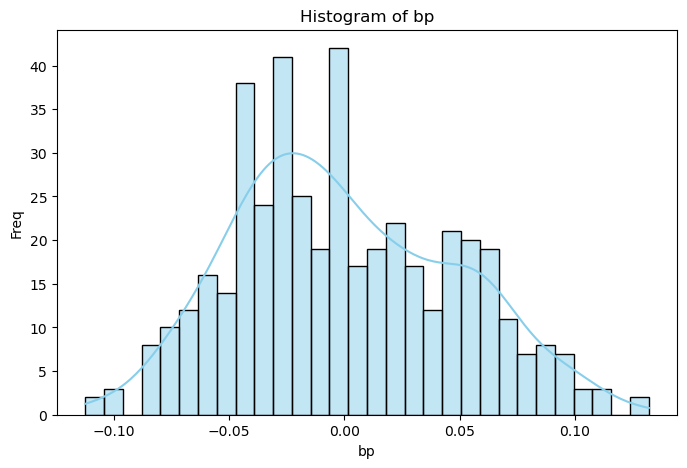

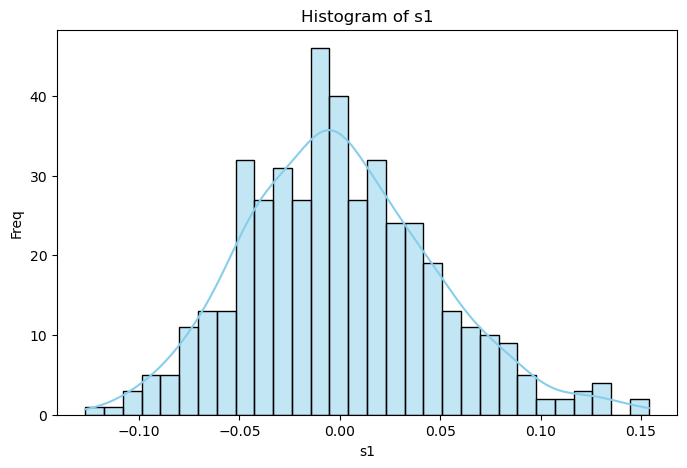

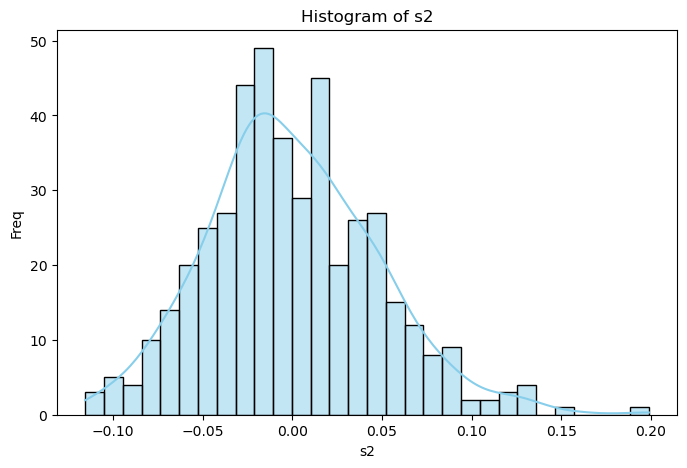

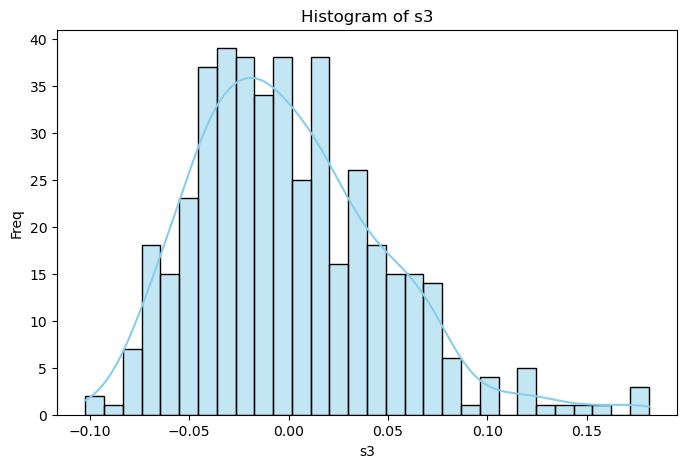

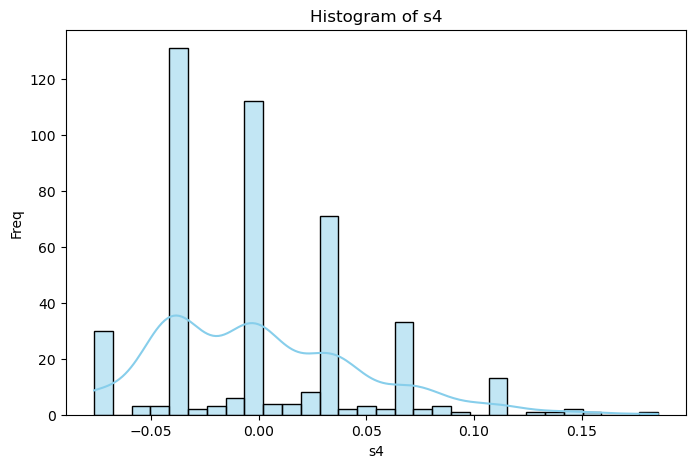

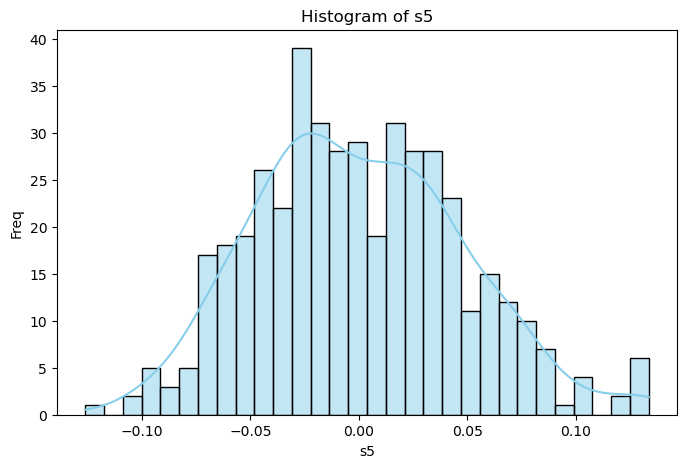

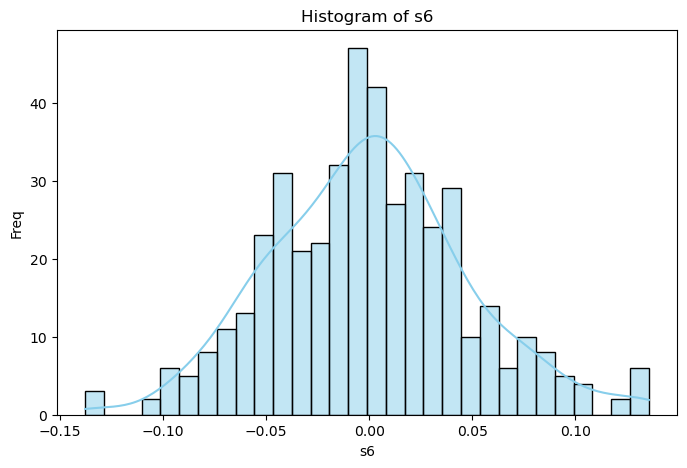

In [ ]:
# continuous variables- Histogram
import seaborn as sns
continuous_vars = ['age', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

for col in continuous_vars:
    plt.figure(figsize=(8,5))
    sns.histplot(df[col], bins=30, kde = True, color="skyblue")
    plt.title(f"Histogram of {col}")
    plt.ylabel("Freq")
    plt.show

In [ ]:
# regression

In [ ]:
# define the models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=1, max_iter=10000),
    "Lasso (alpha=1)": Lasso(alpha=1, max_iter=10000),
    "ElasticNet (alpha=0.5, l1_ratio=0)": ElasticNet(alpha=1.0, l1_ratio=0, max_iter=10000)
}

# train and collect results
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print("Model Coefficients:", np.sum(abs(model.coef_)))
    y_pred = model.predict(X_test_scaled)
    results[name] = {
        "Test R²": r2_score(y_test, y_pred),
        "Test MSE": mean_squared_error(y_test, y_pred),
        "Non-zero Coefficients": np.sum(abs(model.coef_))
    }

pd.DataFrame(results).T.round(4)

Model Coefficients: 183.1196898284974
Model Coefficients: 156.41825646166444
Model Coefficients: 97.26932153735835
Model Coefficients: 64.80367405493418


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.896e+05, tolerance: 2.145e+02
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


,Test R²,Test MSE,Non-zero Coefficients
Linear Regression,0.4526,2900.1936,183.1197
Ridge (alpha=10),0.4541,2892.0146,156.4183
Lasso (alpha=1),0.4669,2824.5681,97.2693
"ElasticNet (alpha=0.5, l1_ratio=0)",0.4316,3011.6479,64.8037


l1 ratio as 0 is ridge and l1 ratio as 1 is lasso
alpha is degree of regularization


[1.00000000e-03 1.32571137e-03 1.75751062e-03 2.32995181e-03
 3.08884360e-03 4.09491506e-03 5.42867544e-03 7.19685673e-03
 9.54095476e-03 1.26485522e-02 1.67683294e-02 2.22299648e-02
 2.94705170e-02 3.90693994e-02 5.17947468e-02 6.86648845e-02
 9.10298178e-02 1.20679264e-01 1.59985872e-01 2.12095089e-01
 2.81176870e-01 3.72759372e-01 4.94171336e-01 6.55128557e-01
 8.68511374e-01 1.15139540e+00 1.52641797e+00 2.02358965e+00
 2.68269580e+00 3.55648031e+00 4.71486636e+00 6.25055193e+00
 8.28642773e+00 1.09854114e+01 1.45634848e+01 1.93069773e+01
 2.55954792e+01 3.39322177e+01 4.49843267e+01 5.96362332e+01
 7.90604321e+01 1.04811313e+02 1.38949549e+02 1.84206997e+02
 2.44205309e+02 3.23745754e+02 4.29193426e+02 5.68986603e+02
 7.54312006e+02 1.00000000e+03]


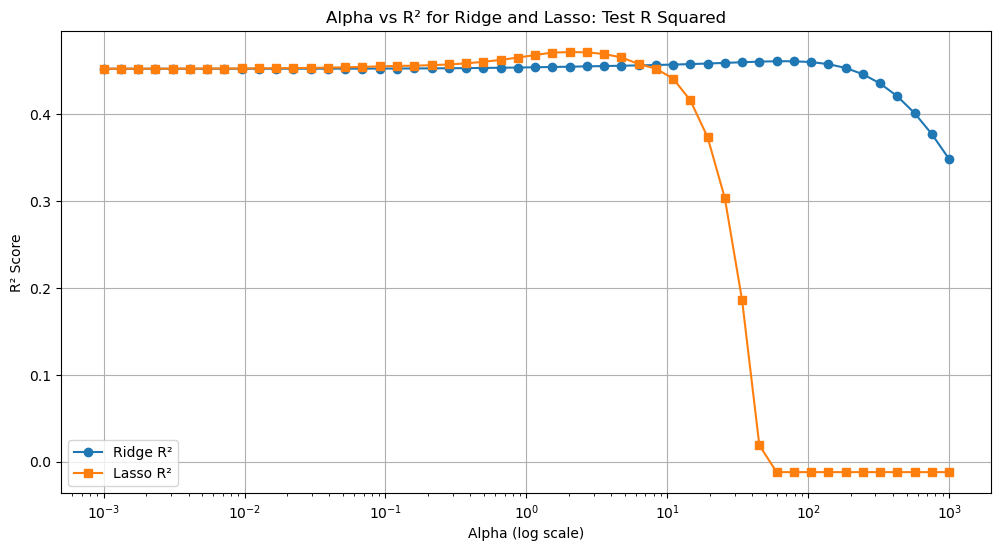

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

alphas = np.logspace(-3, 3, 50)
ridge_scores = []
lasso_scores = []
print(alphas)
for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    ridge_scores.append(ridge.score(X_test_scaled, y_test))

    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)
    lasso_scores.append(lasso.score(X_test_scaled, y_test))

plt.figure(figsize=(12,6))
plt.plot(alphas, ridge_scores, label='Ridge R²', marker='o')
plt.plot(alphas, lasso_scores, label='Lasso R²', marker='s')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R² Score')
plt.title('Alpha vs R² for Ridge and Lasso: Test R Squared')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# generate x as linearly spaced between -1 and 1 and y = x1 *2 + gaussian noise , np.random.noraml and mean and sd of 0.5, generate y as a function of x, regression

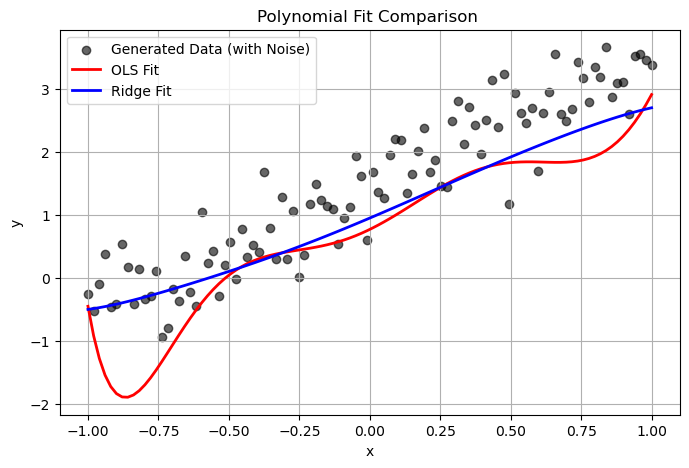

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate data based on whiteboard parameters
np.random.seed(42) # For reproducibility
x = np.linspace(-1, 1, 100)
noise = np.random.normal(loc=0.5, scale=0.5, size=x.shape)
y = 1 + 2 * x + noise

# 2. Recreate the OLS and Ridge polynomial regression equations from the whiteboard:
y_ols = (
    0.77
    + 2.19 * x
    + 3.56 * (x**2)
    - 4.07 * (x**3)
    - 14.4 * (x**4)
    + 11.91 * (x**5)
    + 11.3 * (x**6)
    - 8.35 * (x**7)
)

y_ridge = (
    0.95
    + 1.9 * x
    + 0.3 * (x**2)
    - 0.4 * (x**3)
    - 0.25 * (x**4)
    + 0.3 * (x**5)
    + 0.1 * (x**6)
    - 0.2 * (x**7)
)

# 3. Plot the generated noisy data vs both fitted curves
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='black', label='Generated Data (with Noise)', alpha=0.6)
plt.plot(x, y_ols, color='red', linewidth=2, label='OLS Fit ')
plt.plot(x, y_ridge, color='blue', linewidth=2, label='Ridge Fit')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Fit Comparison ')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# OLS function overfits
# cross-validation
# divide the dataset into n folds, then every fold, one will be the test set ansd all other n-1 fold as train sets


In [ ]:


from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load the breast cancer dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_accuracies = []
validation_accuracies = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    # Split data for this fold
    X_train = X[train_index]
    X_validation = X[validation_index]

    y_train = y[train_index]
    y_validation = y[validation_index]

    model = DecisionTreeClassifier(
        random_state=42
    )

    # Train
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_validation_pred = model.predict(X_validation)

    # Accuracy
    train_accuracy = accuracy_score(y_train, y_train_pred)
    validation_accuracy = accuracy_score(y_validation, y_validation_pred)

    train_accuracies.append(train_accuracy)
    validation_accuracies.append(validation_accuracy)

    print(f"Fold {fold}")
    print(f"Training accuracy : {train_accuracy:.4f}")
    print(f"Validation accuracy : {validation_accuracy:.4f}")
    print(f"Accuracy gap : {train_accuracy - validation_accuracy:.4f}")
    print("-" * 40)


Fold 1
Training accuracy : 1.0000
Validation accuracy : 0.9298
Accuracy gap : 0.0702
----------------------------------------
Fold 2
Training accuracy : 1.0000
Validation accuracy : 0.8684
Accuracy gap : 0.1316
----------------------------------------
Fold 3
Training accuracy : 1.0000
Validation accuracy : 0.8860
Accuracy gap : 0.1140
----------------------------------------
Fold 4
Training accuracy : 1.0000
Validation accuracy : 0.9386
Accuracy gap : 0.0614
----------------------------------------
Fold 5
Training accuracy : 1.0000
Validation accuracy : 0.9292
Accuracy gap : 0.0708
----------------------------------------


In [ ]:
# difference is called generalization error
#